# Week 4 Day 2 - LangGraph, the orchestration layer

Yesterday we met the building blocks. Today we move up to Layer 2 and let LangGraph wire those blocks into a graph that it runs for us, keeping track of state and memory as it goes.

## What LangGraph is

LangGraph lets you describe a piece of work as a graph: a handful of nodes, which are just Python functions, joined by edges that decide what runs next. The framework holds a shared object called the state, passes it from node to node, and can save a snapshot at every step so your application can remember and recover.

It's worth appreciating that LangGraph is agnostic to what it's orchestrating - you don't even need an LLM in the picture!

In [21]:
# Imports and environment first, as always

import os
import random
import requests
from typing import Annotated
from typing_extensions import TypedDict
from dotenv import load_dotenv
from IPython.display import Image, display
import gradio as gr
from langchain_openai import ChatOpenAI
from langchain_community.tools import GoogleSerperRun
from langchain_community.utilities import GoogleSerperAPIWrapper
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver
from langgraph.checkpoint.sqlite import SqliteSaver

load_dotenv(override=True)

True

## The State, and a word about reducers

The state is the object that flows through the graph. We describe it with a `TypedDict`. Each field updates on its own, and by default a new value simply replaces the old one.

Sometimes we want updates to accumulate instead. A reducer is a small function that says how to combine the old value with the new one. We attach it with `Annotated`. LangGraph ships the reducer we want for chat, `add_messages`, which appends new messages to the running list rather than overwriting it.

In [22]:
# Step 1: Define the State object
class State(TypedDict):
    messages: Annotated[list, add_messages]

## Adding tools: a node, a condition, and a loop

To let the model use tools, we add two prebuilt pieces. `ToolNode` is a node that runs whatever tools the model asked for. `tools_condition` is a ready made router that sends the flow to the tools node when the model wants a tool, and to the end when it is finished.

The tools themselves come from two different places, quite deliberately. The search tool comes off the shelf: `langchain-community` ships ready-made tools for hundreds of services, and `GoogleSerperRun` wraps the same Serper API you already have a key for. The push notification tool we write ourselves with the `@tool` decorator, exactly as in lab 1. Notice that both kinds plug into the graph in exactly the same way.

By the way, you may have noticed a deprecation warning when we ran the imports. The `langchain-community` package is gradually being wound down in favor of standalone packages, one per integration, the same way `langchain-openai` ships on its own. It still works well and you will meet it in tutorials all over the web, so it is worth knowing. If you would prefer a fully supported alternative, the `langchain-tavily` package offers a `TavilySearch` tool that does the same job with a free API key from tavily.com.

We bind the tools to the model so it knows they exist, then wire a loop: the chatbot decides, the tools run, and we come back to the chatbot so it can see the results and continue.

In [23]:
llm = ChatOpenAI(model="gpt-5.4-mini")
search = GoogleSerperRun(api_wrapper=GoogleSerperAPIWrapper())

@tool
def send_push_notification(text: str) -> str:
    """Send a short push notification to the user's phone."""
    requests.post(
        "https://api.pushover.net/1/messages.json",
        data={"token": os.getenv("PUSHOVER_TOKEN"), "user": os.getenv("PUSHOVER_USER"), "message": text},
    )
    return "Notification sent"


@tool
def get_weather(city: str) -> str:
    """Return a fictional weather report for a given city."""
    fake_weather = {
        "london": "Rainy, 12°C",
        "lima": "Cloudy, 19°C",
        "madrid": "Sunny, 28°C",
        "paris": "Foggy, 14°C",
    }
    return fake_weather.get(city.lower(), "Unknown city: no weather data")

print(get_weather.invoke({"city": "Lima"}))

tools = [search, send_push_notification, get_weather]
llm_with_tools = llm.bind_tools(tools)

Cloudy, 19°C


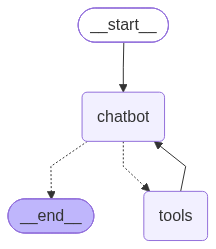

In [24]:
def chatbot_node(state: State) -> dict:
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

builder = StateGraph(State)

builder.add_node("chatbot", chatbot_node)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "chatbot")
builder.add_conditional_edges("chatbot", tools_condition)
builder.add_edge("tools", "chatbot")

graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [25]:
question = (
    "Use your search tool to find which city the Eiffel Tower is in, "
    "then get the weather for that city, "
    "and finally send me a push notification with the weather."
)

step = 0
for update in graph.stream({"messages": [{"role": "user", "content": question}]}, stream_mode="updates"):
    for node, output in update.items():
        step += 1
        messages = output.get("messages", [])
        calls = [c["name"] for m in messages for c in getattr(m, "tool_calls", [])]
        print(f"step {step:>2}  node={node:<10}  tool_calls={calls or '-'}")


step  1  node=chatbot     tool_calls=['google_serper']
step  2  node=tools       tool_calls=-
step  3  node=chatbot     tool_calls=['get_weather']
step  4  node=tools       tool_calls=-
step  5  node=chatbot     tool_calls=['send_push_notification']
step  6  node=tools       tool_calls=-
step  7  node=chatbot     tool_calls=-


## A second LLM node: the translator

Nodes do not have to be part of the tool loop. Any function can be a node, including one that makes its own LLM call. To prove it, we will add a translator that writes a Spanish version of the final answer into the state.

Two things are new here. First, the state gains a second field, `spanish`. It has no reducer, so each run simply overwrites it, which is just what we want. Second, until now `tools_condition` has sent the finished conversation straight to `END`. By passing a mapping as the third argument, we send that branch through the translator instead, and the translator ends the run.

Look closely at the rendered graph this time. There are two nodes that call an LLM: the chatbot, which has tools and sits in a loop, and the translator, which makes one plain call on the way out. And since the translator runs after the chatbot has finished, it gets a super-step of its own.

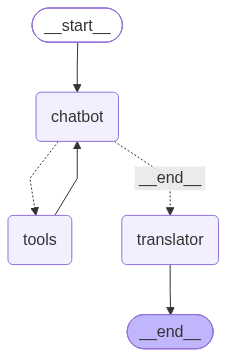

In [26]:
class State(TypedDict):
    messages: Annotated[list, add_messages]
    spanish: str

def translator_node(state: State) -> dict:
    last = state["messages"][-1].content
    prompt = f"Translate this into Spanish, replying with the translation only:\n\n{last}"
    return {"spanish": llm.invoke(prompt).content}

builder = StateGraph(State)

builder.add_node("chatbot", chatbot_node)
builder.add_node("tools", ToolNode(tools))
builder.add_node("translator", translator_node)

builder.add_edge(START, "chatbot")
builder.add_conditional_edges("chatbot", tools_condition, {"tools": "tools", END:"translator"})
builder.add_edge("tools", "chatbot")
builder.add_edge("translator", END)
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [27]:
result = graph.invoke({"messages": [{"role": "user", "content": "In one sentence, what is weather in Paris?"}]})
print(result["messages"][-1].content)
print(result["spanish"])

Paris is foggy and 14°C.
París está cubierto de niebla y tiene 14 °C.


<table style="margin: 0; text-align: left; width:100%">
    <tr>
        <td style="width: 150px; height: 150px; vertical-align: middle;">
            <img src="../assets/tools.png" width="150" height="150" style="display: block;" />
        </td>
        <td>
            <h2 style="color:#00bfff;">Observability with LangSmith</h2>
            <span style="color:#00bfff;">LangSmith records every model and tool call so you can see exactly what your graph did. Sign up at <a href="https://smith.langchain.com">smith.langchain.com</a>, create an API key, and add these lines to your <code>.env</code> file:<br/><br/>
            <code>LANGSMITH_TRACING=true</code><br/>
            <code>LANGSMITH_ENDPOINT=https://api.smith.langchain.com</code></br>
            <code>LANGSMITH_API_KEY=lsv2_...</code><br/>
            <code>LANGSMITH_PROJECT=agentic-track</code><br/><br/>
            That is all. Every LangChain and LangGraph run is then traced automatically with no change to your code, and you can watch it unfold on the LangSmith dashboard. We will not run this here, but it is well worth turning on for your own work.
            </span>
        </td>
    </tr>
</table>

## Memory: why the graph forgets, and how to fix it

Try chatting twice with the graph above and it will not remember the first exchange. That feels odd, because the state was carefully passing messages along. The reason is that one call to `invoke` is one run of the graph: a sequence of super-steps, one for each layer of nodes that executes (the LLM call is one super-step; the tool calls it requests run together in the next). The reducer accumulates messages within that run, but the next `invoke` starts fresh.

To remember across calls we add a checkpointer. It saves a snapshot of the state after every super-step, filed under a `thread_id`. Give it the same `thread_id` next time and the saved history is loaded before your new message is added.

In [29]:
memory = MemorySaver()

builder = StateGraph(State)
builder.add_node("chatbot", chatbot_node)
builder.add_node("tools", ToolNode(tools))
builder.add_node("translator", translator_node)
builder.add_edge(START, "chatbot")
builder.add_conditional_edges("chatbot", tools_condition, {"tools": "tools", END: "translator"})
builder.add_edge("translator", END)
builder.add_edge("tools", "chatbot")
graph = builder.compile(checkpointer=memory)

paris_config = {"configurable": {"thread_id": "paris-test"}}

question = (
    "Use your search tool to find which city the Eiffel Tower is in, "
    "then get the weather for that city, "
    "and finally send me a push notification with the weather."
)

first = graph.invoke({"messages": [{"role": "user", "content": question}]}, paris_config)
print(first["messages"][-1].content)


Done — I found that the Eiffel Tower is in **Paris**, got the weather there, and sent you a push notification.

Weather for Paris: **Foggy, 14°C**


In [30]:
second = graph.invoke(
    {"messages": [{"role": "user", "content": "Which city did you find, and what was its weather?"}]},
    paris_config,
)
print(second["messages"][-1].content)

print("Messages stored in thread:", len(graph.get_state(paris_config).values["messages"]))


I found **Paris**. Its weather was **Foggy, 14°C**.
Messages stored in thread: 10


In [31]:
for i, m in enumerate(graph.get_state(paris_config).values["messages"], start=1):
    calls = [c["name"] for c in getattr(m, "tool_calls", [])]
    print(f"{i:>2}  {m.type:<6}  tool_calls={calls or '-'}  {str(m.content)[:60]!r}")


 1  human   tool_calls=-  'Use your search tool to find which city the Eiffel Tower is '
 2  ai      tool_calls=['google_serper']  ''
 3  tool    tool_calls=-  'The Eiffel Tower (/ˈaɪfəl/ EYE-fəl; French: Tour Eiffel [tuʁ'
 4  ai      tool_calls=['get_weather']  ''
 5  tool    tool_calls=-  'Foggy, 14°C'
 6  ai      tool_calls=['send_push_notification']  ''
 7  tool    tool_calls=-  'Notification sent'
 8  ai      tool_calls=-  'Done — I found that the Eiffel Tower is in **Paris**, got th'
 9  human   tool_calls=-  'Which city did you find, and what was its weather?'
10  ai      tool_calls=-  'I found **Paris**. Its weather was **Foggy, 14°C**.'


In [32]:
history = list(graph.get_state_history(paris_config))
print("Number of saved checkpoints:", len(history))

for h in reversed(history):
    m = h.metadata
    queued = ", ".join(t.name for t in h.tasks) or "(run complete)"
    print(f"step {m['step']:>2}  {m['source']:<5}  messages={len(h.values.get('messages', []))}  about to run: {queued}")


Number of saved checkpoints: 14
step -1  input  messages=0  about to run: __start__
step  0  loop   messages=1  about to run: chatbot
step  1  loop   messages=2  about to run: tools
step  2  loop   messages=3  about to run: chatbot
step  3  loop   messages=4  about to run: tools
step  4  loop   messages=5  about to run: chatbot
step  5  loop   messages=6  about to run: tools
step  6  loop   messages=7  about to run: chatbot
step  7  loop   messages=8  about to run: translator
step  8  loop   messages=8  about to run: (run complete)
step  9  input  messages=8  about to run: __start__
step 10  loop   messages=9  about to run: chatbot
step 11  loop   messages=10  about to run: translator
step 12  loop   messages=10  about to run: (run complete)


## Persisting to SQLite

`MemorySaver` keeps everything in memory, which vanishes when the program stops. For something durable we swap in the SQLite checkpointer, which writes to a database file. The same graph code now survives restarts. A file called `memory.db` appears next to this notebook, and you can delete it whenever you like.

In [33]:
with SqliteSaver.from_conn_string("memory.db") as sql_memory:
    durable_graph = builder.compile(checkpointer=sql_memory)
    sql_config = {"configurable": {"thread_id": "conversation-2"}}
    durable_graph.invoke({"messages": [{"role": "user", "content": "Remember that my favorite color is orange."}]}, sql_config)
    reply = durable_graph.invoke({"messages": [{"role": "user", "content": "What is my favorite color?"}]}, sql_config)
    print(reply["messages"][-1].content)
    print(reply["spanish"])

Your favorite color is orange.
Tu color favorito es naranja.


## Looking inside the state, and travelling back in time

Because the checkpointer saves a snapshot at every super-step, you can inspect the current state and walk the whole history. Each entry carries a `checkpoint_id`, and by putting one of those into the config you can rerun the graph from that exact moment. This is what lets LangGraph applications recover and branch from any earlier point.

In [ ]:
snapshot = graph.get_state(paris_config)
messages = snapshot.values["messages"]
print("Messages stored so far:", len(messages))

for message in messages:
    print(message.content)

history = list(graph.get_state_history(paris_config))
print("Number of saved checkpoints:", len(history))


Messages stored so far: 10
Use your search tool to find which city the Eiffel Tower is in, then get the weather for that city, and finally send me a push notification with the weather.

The Eiffel Tower (/ˈaɪfəl/ EYE-fəl; French: Tour Eiffel [tuʁ ɛfɛl] ) is a lattice tower on the Champ de Mars in Paris, France. It is named after the ... The Eiffel Tower is open in the evening: enjoy a magical visit high above the City of Light in a more relaxed atmosphere. The tower is situated in 7th arrondissement, one of the French capital's chicest districts, 75007 Paris, France The Eiffel Tower in Paris, France, has serious celeb status. Completed in March 1889, it's one of the most recognizable monuments in the world. Eiffel Tower—the most ionic landmark in the French capital. is presently in New York was first in Paris. it was originally named the Tower of ... Located in Paris - France. It is Paris city capital of France where Eiffel tower is erected. Built for the Universal Exhibition of 1889, 

In [35]:
for h in reversed(history):            # history is newest first; reversed reads as a story
      m = h.metadata
      queued = ", ".join(t.name for t in h.tasks) or "(run complete)"
      print(f"step {m['step']:>2}  {m['source']:<5}  messages={len(h.values.get('messages', []))}  about to run: {queued}")

step -1  input  messages=0  about to run: __start__
step  0  loop   messages=1  about to run: chatbot
step  1  loop   messages=2  about to run: tools
step  2  loop   messages=3  about to run: chatbot
step  3  loop   messages=4  about to run: tools
step  4  loop   messages=5  about to run: chatbot
step  5  loop   messages=6  about to run: tools
step  6  loop   messages=7  about to run: chatbot
step  7  loop   messages=8  about to run: translator
step  8  loop   messages=8  about to run: (run complete)
step  9  input  messages=8  about to run: __start__
step 10  loop   messages=9  about to run: chatbot
step 11  loop   messages=10  about to run: translator
step 12  loop   messages=10  about to run: (run complete)


In [38]:
# Time travel: take a checkpoint from earlier and resume the graph from that exact moment
earlier = next(h for h in history if h.metadata["step"] == 8)

print("A checkpoint from earlier held", len(earlier.values["messages"]), "messages")

replay_config = {"configurable": {"thread_id": "paris-test",
                                  "checkpoint_id": earlier.config["configurable"]["checkpoint_id"]}}
resumed = graph.invoke(None, replay_config)
print("Resumed from the past; the graph now holds", len(resumed["messages"]), "messages")

again = graph.invoke({"messages": [{"role": "user", "content": "What do you know about me?"}]}, replay_config)
print(again["messages"][-1].content)
print(again["spanish"])


A checkpoint from earlier held 8 messages
Resumed from the past; the graph now holds 8 messages
I only know what you’ve told me in this conversation.

So far, I know:
- You asked me to find the city of the Eiffel Tower
- You wanted the weather for that city
- You wanted a push notification sent with that weather

I don’t have access to personal data about you unless you share it with me here.
Solo sé lo que me has dicho en esta conversación.

Hasta ahora, sé:
- Me pediste que encontrara la ciudad de la Torre Eiffel
- Quisiste el clima de esa ciudad
- Quisiste que se enviara una notificación push con ese clima

No tengo acceso a datos personales sobre ti a menos que los compartas conmigo aquí.


## Adding a UI

Let's add a simple Gradio UI to bring this to life. The `chat` function kicks off one run of the graph per message, using a fixed `thread_id` so the conversation is remembered, and it shows the Spanish translation in italics beneath each reply.

In [ ]:
def chat(user_input: str, history):
    config = {"configurable": {"thread_id": "gradio-session4"}}
    result = graph.invoke({"messages": [{"role": "user", "content": user_input}]}, config)
    return f"{result['messages'][-1].content}\n\n*{result['spanish']}*"

gr.ChatInterface(chat).launch()

* Running on local URL:  http://127.0.0.1:7862
* To create a public link, set `share=True` in `launch()`.


## Recap, and where we are heading

You have built graphs by hand: state with a reducer, nodes, edges, a conditional edge, a tool loop, a second LLM node, observability, memory in two flavors, and a way to inspect and replay the whole thing. This is the machinery that powers everything above it.

Tomorrow we reach Layer 3, our next step along the control to convenience spine. We will ask `create_agent` to build a graph exactly like the tool loop above, in a single line, and then we will render that graph and recognise it as our own.

<table style="margin: 0; text-align: left; width:100%">
    <tr>
        <td style="width: 150px; height: 150px; vertical-align: middle;">
            <img src="../assets/exercise.png" width="150" height="150" style="display: block;" />
        </td>
        <td>
            <h2 style="color:#ff7800;">Exercise</h2>
            <span style="color:#ff7800;">Add a third tool to the graph, then ask the assistant a question that needs a search followed by a push notification and uses your tool, so the tool loop runs more than once. Then open the LangSmith dashboard, if you turned it on, and trace exactly which nodes ran and in what order.
            </span>
        </td>
    </tr>
</table>